# 4. Deepchecks: integridade, drift, desempenho e monitoramento mensal

Objetivos principais:
- Carregar o dataset limpo e o modelo treinado em 2011 (`pipeline_2011.joblib`);
- Definir a **janela de referência** (holdout de 2011) e a **produção** (2012 inteiro);
- Rodar as três suítes prontas do Deepchecks e salvar os relatórios HTML em `runs/`:
  - **Data Integrity** → qualidade do lote de produção;
  - **Train-Test Validation** → *Feature Drift*, *Label Drift*, drift multivariado, vazamento por data;
  - **Model Evaluation** → desempenho, distribuição dos erros, segmentos fracos;
- Montar um **gate de produção (PASS/FAIL)** com regras explícitas;
- **Monitorar 2012 mês a mês**, comparando cada mês com o mesmo mês de 2011;
- Testar **o que fazer** quando o gate reprova: re-treino ingênuo, janela recente e recalibração.

### Evidently × Deepchecks (mapa rápido)

| Evidently | Deepchecks |
|---|---|
| `Report` + `DataDriftPreset` | suíte `train_test_validation()` (`FeatureDrift`, `MultivariateDrift`) |
| `TargetDriftPreset` | `LabelDrift` (rótulo real) e `PredictionDrift` (saída do modelo) |
| `RegressionPreset` | suíte `model_evaluation()` (`TrainTestPerformance`, `RegressionErrorDistribution`, `WeakSegmentsPerformance`...) |
| (sem equivalente direto) | suíte `data_integrity()` |
| `TestSuite` + `Test*(lt=..., gt=...)` | `Suite` com **conditions**: `check.add_condition_*(...)` |
| recebe colunas `target` / `prediction` prontas | recebe o **modelo** e calcula as predições (por isso o `CountModel`) |

In [1]:
# Imports
import sys
from pathlib import Path
import json
import warnings
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error

warnings.filterwarnings("ignore")  # o Deepchecks é bem verboso com FutureWarnings do sklearn/pandas

sys.path.append("..")
from src.bike import FEATURES, CAT_FEATURES, LABEL, CountModel, ScaledModel, build_pipeline, rmse

try:
    import deepchecks
    from deepchecks.tabular import Dataset, Suite
    from deepchecks.tabular.suites import data_integrity, train_test_validation, model_evaluation
    from deepchecks.tabular.checks import (
        FeatureDrift, LabelDrift, PredictionDrift, MultivariateDrift, NewCategoryTrainTest,
        TrainTestPerformance, RegressionErrorDistribution, PercentOfNulls, DataDuplicates,
    )
    DEEPCHECKS_AVAILABLE = True
    print("Deepchecks versão:", deepchecks.__version__)
except Exception as e:
    DEEPCHECKS_AVAILABLE = False
    print("Erro ao carregar Deepchecks:", e)

BLUE, ORANGE, AQUA, YELLOW, GRAY = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#52514e"
print("Deepchecks disponível:", DEEPCHECKS_AVAILABLE)

Deepchecks versão: 0.19.1
Deepchecks disponível: True


## 1 — Carregar dados, modelo e métricas

In [2]:
DATA_PATH = Path("..") / "data" / "processed" / "bike_clean.parquet"
MODEL_PATH = Path("..") / "models" / "pipeline_2011.joblib"
METRICS_PATH = Path("..") / "models" / "metrics.json"
RUNS_DIR = Path("..") / "runs"
RUNS_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_parquet(DATA_PATH)
pipe = joblib.load(MODEL_PATH)
metrics = json.loads(METRICS_PATH.read_text())

# O modelo devolve aluguéis por hora; a correção de viés só entra se a validação aprovou
model = CountModel(pipe, metrics["sigma_used"])
print("Dados:", df.shape)
print("Correção de viés no modelo:", metrics["use_bias_correction"], "| sigma usado:", metrics["sigma_used"])
print("Treino:", metrics["train_window"])
print("Referência:", metrics["reference_window"])

Dados: (17379, 17)
Correção de viés no modelo: False | sigma usado: 0.0
Treino: 2011, dias 1 a 23 de cada mês
Referência: 2011, dias 24 em diante de cada mês (holdout)


## 2 — Janelas e `Dataset` do Deepchecks

| Janela | Período | Papel nas suítes |
|---|---|---|
| **Treino** | 2011, dias 1–23 de cada mês | só para treinar (não entra nas suítes) |
| **Referência** | 2011, dias 24+ de cada mês (holdout) | `train_dataset` |
| **Produção** | 2012 inteiro | `test_dataset` |

Passamos ao `Dataset`:
- `features` explícitas (assim `casual`, `registered` e `year` nunca entram, nem por engano);
- `cat_features` explícitas, incluindo `holiday` e `workingday` (são 0/1, não grandezas);
- `datetime_name='datetime'`, que habilita as checagens de vazamento por data.

In [3]:
DC_CAT = CAT_FEATURES + ["holiday", "workingday"]

def make_ds(d):
    return Dataset(d[FEATURES + [LABEL, "datetime"]].reset_index(drop=True), label=LABEL,
                   features=FEATURES, cat_features=DC_CAT, datetime_name="datetime")

is_2011, is_2012 = df["year"] == 2011, df["year"] == 2012
ref_data = df[is_2011 & (df["date"].dt.day >= 24)].reset_index(drop=True)
cur_data = df[is_2012].reset_index(drop=True)
print(f"Referência (holdout 2011): {len(ref_data)} horas | Produção (2012): {len(cur_data)} horas")

ref_ds, cur_ds = make_ds(ref_data), make_ds(cur_data)
ref_ds

Referência (holdout 2011): 2083 horas | Produção (2012): 8734 horas


,Column,DType,Kind,Additional Info
0,datetime,datetime64,Datetime,
1,cnt,integer,,
2,hour,integer,Numerical Feature,
3,month,integer,Numerical Feature,
4,holiday,integer,Categorical Feature,
5,workingday,integer,Categorical Feature,
6,temp,floating,Numerical Feature,
7,atemp,floating,Numerical Feature,
8,humidity,floating,Numerical Feature,
9,windspeed,floating,Numerical Feature,


## 3 — Importância das features

Várias checagens ponderam ou ordenam as features pela importância. Calculamos *permutation importance* uma única vez, na referência, e passamos a todas as suítes (senão o Deepchecks recalcula a cada execução).

In [4]:
def neg_mae(est, X, y):
    return -mean_absolute_error(y, est.predict(X))

pi = permutation_importance(model, ref_data[FEATURES], ref_data[LABEL], scoring=neg_mae,
                            n_repeats=5, random_state=42)
feature_importance = pd.Series(pi.importances_mean, index=FEATURES).clip(lower=0)
feature_importance = feature_importance / feature_importance.sum()
feature_importance.sort_values(ascending=False).round(3).to_frame("importância")

,importância
hour,0.598
workingday,0.138
month,0.061
temp,0.055
humidity,0.050
atemp,0.036
weekday,0.023
season,0.018
weather,0.016
windspeed,0.004


## 4 — Suítes prontas do Deepchecks

Cada suíte roda dezenas de checagens e gera um HTML interativo. As checagens já vêm com **conditions** padrão; a função `resumo()` lista só as que **não** passaram, para não precisar abrir o HTML para ter a visão geral.

In [5]:
def resumo(result, so_problemas=True):
    """Tabela com as conditions de um SuiteResult."""
    rows = []
    for res in result.results:
        header = res.get_header() if hasattr(res, "get_header") else getattr(res, "header", "?")
        if hasattr(res, "exception"):  # CheckFailure: checagem não se aplica ou falhou
            msg = str(res.exception)
            na = any(t in msg for t in ["irrelevant", "does not contain an index", "is relevant for"])
            rows.append({"checagem": header, "condição": "-", "status": "N/A" if na else "ERROR", "detalhe": msg[:150]})
            continue
        for cond in res.conditions_results:
            rows.append({"checagem": header, "condição": cond.name, "status": cond.category.name, "detalhe": cond.details})
    out = pd.DataFrame(rows, columns=["checagem", "condição", "status", "detalhe"])
    if so_problemas:
        out = out[~out["status"].isin(["PASS", "N/A"])]
    return out.reset_index(drop=True)

pd.set_option("display.max_colwidth", 160)

def salvar(result, nome):
    path = RUNS_DIR / f"{nome}.html"
    path.unlink(missing_ok=True)  # o Deepchecks não sobrescreve: criaria "nome (1).html"
    result.save_as_html(str(path), as_widget=False)
    print("Relatório salvo em:", path)

### 4.1 Data Integrity — qualidade do lote de produção (2012)

In [6]:
if DEEPCHECKS_AVAILABLE:
    integrity_result = data_integrity().run(cur_ds)
    salvar(integrity_result, "deepchecks_data_integrity")
    display(resumo(integrity_result))

Relatório salvo em: ../runs/deepchecks_data_integrity.html


,checagem,condição,status,detalhe
0,Feature-Feature Correlation,Not more than 0 pairs are correlated above 0.9,FAIL,"Correlation is greater than 0.9 for pairs [('atemp', 'temp')]"
1,Identifier Label Correlation,Identifier columns PPS is less or equal to 0,FAIL,Found 1 out of 1 columns with PPS above threshold: {'datetime': '0.36'}


**Leitura:** nenhum problema de qualidade "clássico" (nulos, duplicados, tipos mistos, *string mismatch*). As duas falhas dizem mais sobre o **comportamento** dos dados do que sobre sujeira:

- **`Feature-Feature Correlation`**: `temp` × `atemp` com correlação > 0.9. Esperado (sensação térmica deriva da temperatura) e já visto na EDA. Não é erro; dá para remover uma das duas sem perda.
- **`Identifier Label Correlation`**: só o `datetime` já prevê parte do `cnt` em 2012 (PPS = 0.36). Num sistema estável a data sozinha não deveria prever nada; aqui ela captura o **crescimento ao longo de 2012**. É o primeiro sinal do problema, e aparece sem nem precisar comparar com 2011.

Checagens que não se aplicam a regressão (ex.: `Conflicting Labels`) aparecem como `N/A` e ficam fora do resumo.

### 4.2 Train-Test Validation — drift entre Referência (2011) e Produção (2012)

In [7]:
if DEEPCHECKS_AVAILABLE:
    drift_result = train_test_validation().run(ref_ds, cur_ds, feature_importance=feature_importance)
    salvar(drift_result, "deepchecks_train_test_validation")
    display(resumo(drift_result))

Relatório salvo em: ../runs/deepchecks_train_test_validation.html


,checagem,condição,status,detalhe
0,Label Drift,Label drift score < 0.15,FAIL,Label's drift score Kolmogorov-Smirnov is 0.21
1,Multivariate Drift,Drift value is less than 0.25,FAIL,"Found drift value of: 0.3, corresponding to a domain classifier AUC of: 0.65"


**Leitura:**

- **`Label Drift` = 0.21 (FAIL):** a distribuição de `cnt` mudou bastante de 2011 para 2012, como a EDA mostrou.
- **`Multivariate Drift` = 0.30 (AUC 0.65):** falha no limite **padrão** do Deepchecks (0.25), puxado por `humidity` e `atemp`. É um drift leve; no gate usamos um limite mais tolerante (0.75).
- **`Feature Drift`:** nenhuma feature isolada passa de 0.2 (a maior fica abaixo de 0.1).
- **Vazamento por data:** passa, porque 2011 e 2012 não se sobrepõem.

As **entradas mudaram pouco; o target mudou muito.** Esse é o padrão de *concept drift*.

### 4.3 Model Evaluation — desempenho do modelo em 2012

In [8]:
if DEEPCHECKS_AVAILABLE:
    eval_result = model_evaluation().run(ref_ds, cur_ds, model=model, feature_importance=feature_importance)
    salvar(eval_result, "deepchecks_model_evaluation")
    display(resumo(eval_result))

Relatório salvo em: ../runs/deepchecks_model_evaluation.html


,checagem,condição,status,detalhe
0,Train Test Performance,Train-Test scores relative degradation is less than 0.1,FAIL,3 scores failed. Found max degradation of 254.83% for metric Neg MAE
1,Regression Error Distribution - Train Dataset,Systematic error ratio lower than 0.01,FAIL,Found systematic error to rmse ratio of 0.03
2,Regression Error Distribution - Test Dataset,Systematic error ratio lower than 0.01,FAIL,Found systematic error to rmse ratio of 0.68
3,Weak Segments Performance - Train Dataset,The relative performance of weakest segment is greater than 80% of average model performance.,WARN,Found a segment with neg rmse score of -87.619 in comparison to an average score of -41.126 in sampled data.
4,Weak Segments Performance - Test Dataset,The relative performance of weakest segment is greater than 80% of average model performance.,WARN,Found a segment with neg rmse score of -249.381 in comparison to an average score of -130.215 in sampled data.


**Leitura:**

- **`Train Test Performance`:** RMSE 41 → 130, MAE 26 → 93 (+255%), R² 0.91 → 0.61.
- **`Regression Error Distribution`:** em 2012 o erro médio é **68% do RMSE**, ou seja, o erro é quase todo **viés**: o modelo subestima 2012 de forma sistemática. Na referência essa razão é só 0.03. A condição padrão do Deepchecks (< 0.01) é tão rígida que até a referência falha; no gate usamos 0.30.
- **`Weak Segments Performance`** mostra **onde** o modelo erra mais. Em 2012, o pior segmento é **quarta a sexta, das 17h às 19h** (RMSE ≈ 249 contra 130 de média): o pico de volta do trabalho, horário dos usuários cadastrados, que cresceram 68%. Na referência, o pior segmento é bem mais brando (novembro, a partir das 7h: RMSE ≈ 88 contra 41).
- **`Boosting Overfit`** fica `N/A`: o Deepchecks só reconhece modelos de boosting "crus", não o nosso wrapper.

## 5 — Gate de produção (PASS / FAIL)

Equivalente à `TestSuite` do Evidently: poucas regras explícitas, cada uma com uma **condition**. O lote só é aprovado se todas passarem.

| Checagem | Regra | O que pega |
|---|---|---|
| `FeatureDrift` | no máximo 2 features com drift ≥ 0.2 | mudança nas entradas |
| `MultivariateDrift` | drift global < 0.75 | mudança conjunta das entradas |
| `NewCategoryTrainTest` | ≤ 1% de linhas com categoria nova | categorias nunca vistas |
| `PredictionDrift` | drift das previsões < 0.15 | mudança na saída do modelo (não precisa do rótulo) |
| `LabelDrift` | drift do `cnt` real < 0.15 | mudança no target (precisa do rótulo) |
| `TrainTestPerformance` | degradação relativa de RMSE/MAE/R² < 30% | perda de desempenho |
| `RegressionErrorDistribution` | erro médio < 30% do RMSE | erro **sistemático** (viés) |
| `PercentOfNulls` / `DataDuplicates` | ≤ 5% de nulos por coluna; ≤ 1% de duplicados | integridade básica |

In [9]:
def gate_suite(nome="Gate de produção"):
    return Suite(
        nome,
        FeatureDrift().add_condition_drift_score_less_than(0.2, 0.2, allowed_num_features_exceeding_threshold=2),
        MultivariateDrift().add_condition_overall_drift_value_less_than(0.75),
        NewCategoryTrainTest().add_condition_new_category_ratio_less_or_equal(0.01),
        PredictionDrift().add_condition_drift_score_less_than(0.15),
        LabelDrift().add_condition_drift_score_less_than(0.15),
        TrainTestPerformance().add_condition_train_test_relative_degradation_less_than(0.30),
        RegressionErrorDistribution().add_condition_systematic_error_ratio_to_rmse_less_than(0.30),
        PercentOfNulls().add_condition_percent_of_nulls_not_greater_than(0.05),
        DataDuplicates().add_condition_ratio_less_or_equal(0.01),
    )

if DEEPCHECKS_AVAILABLE:
    gate_result = gate_suite("Gate de produção — 2012").run(
        ref_ds, cur_ds, model=model, feature_importance=feature_importance
    )
    salvar(gate_result, "deepchecks_gate")
    gate_table = resumo(gate_result, so_problemas=False)
    gate_table.to_csv(RUNS_DIR / "deepchecks_gate_summary.csv", index=False)

    aprovado = gate_result.passed(fail_if_warning=False)
    print("\n>>> LOTE 2012", "APROVADO" if aprovado else "REPROVADO", "<<<")
    display(gate_table)

Relatório salvo em: ../runs/deepchecks_gate.html

>>> LOTE 2012 REPROVADO <<<


,checagem,condição,status,detalhe
0,Label Drift,Label drift score < 0.15,FAIL,Label's drift score Kolmogorov-Smirnov is 0.21
1,Train Test Performance,Train-Test scores relative degradation is less than 0.3,FAIL,3 scores failed. Found max degradation of 254.83% for metric Neg MAE
2,Regression Error Distribution - Test Dataset,Systematic error ratio lower than 0.3,FAIL,Found systematic error to rmse ratio of 0.68
3,Feature Drift,categorical drift score < 0.2 and numerical drift score < 0.2,PASS,"Passed for 11 columns out of 11 columns.\nFound column ""weather"" has the highest categorical drift score: 0.04\nFound column ""humidity"" has the highest nume..."
4,Multivariate Drift,Drift value is less than 0.75,PASS,"Found drift value of: 0.3, corresponding to a domain classifier AUC of: 0.65"
5,New Category Train Test,Ratio of samples with a new category is less or equal to 1%,PASS,Passed for 5 relevant features
6,Prediction Drift,Prediction drift score < 0.15,PASS,Found model prediction Kolmogorov-Smirnov drift score of 0.03
7,Regression Error Distribution - Train Dataset,Systematic error ratio lower than 0.3,PASS,Found systematic error to rmse ratio of 0.03
8,PercentOfNulls - Train Dataset,Percent of null values in each column is not greater than 5%,PASS,Passed for 11 relevant columns
9,PercentOfNulls - Test Dataset,Percent of null values in each column is not greater than 5%,PASS,Passed for 11 relevant columns


### Números por trás do gate

`SuiteResult` permite ler os valores de cada checagem, útil para logar em um sistema de monitoramento ou travar um pipeline de CI/CD.

In [10]:
def get(result, prefix):
    return next(r for r in result.results if r.get_header().startswith(prefix))

if DEEPCHECKS_AVAILABLE:
    perf = get(gate_result, "Train Test Performance").value
    perf_table = perf.pivot_table(index="Metric", columns="Dataset", values="Value").rename(
        columns={"Train": "Referência 2011", "Test": "Produção 2012"})
    perf_table.loc[["Neg RMSE", "Neg MAE"]] *= -1
    perf_table = perf_table.rename(index={"Neg RMSE": "RMSE", "Neg MAE": "MAE"}).round(3)
    display(perf_table)

    p_ref, p_cur = model.predict(ref_data), model.predict(cur_data)
    print(f"viés da soma prevista — referência: {p_ref.sum() / ref_data[LABEL].sum() - 1:+.1%} | "
          f"produção: {p_cur.sum() / cur_data[LABEL].sum() - 1:+.1%}")

    drift_scores = pd.Series({
        "LabelDrift (cnt real)": get(gate_result, "Label Drift").value["Drift score"],
        "PredictionDrift (previsões)": get(gate_result, "Prediction Drift").value["Drift score"],
        "FeatureDrift (máximo entre features)": max(v["Drift score"] for v in get(gate_result, "Feature Drift").value.values()),
    }).round(3)
    display(drift_scores.to_frame("drift score"))

Dataset,Produção 2012,Referência 2011
Metric,,
MAE,92.998,26.210
RMSE,130.215,41.126
R2,0.611,0.909


viés da soma prevista — referência: -0.9% | produção: -37.9%


,drift score
LabelDrift (cnt real),0.212
PredictionDrift (previsões),0.026
FeatureDrift (máximo entre features),0.087


### Leitura do gate

O lote de 2012 é **reprovado** por três regras, todas ligadas ao rótulo real:

| Reprovou | Passou |
|---|---|
| `LabelDrift` (0.21) | `FeatureDrift` (nenhuma feature ≥ 0.2) |
| `TrainTestPerformance` (MAE +255%) | `MultivariateDrift` (0.30 < 0.75) |
| `RegressionErrorDistribution` (erro sistemático = 68% do RMSE) | `PredictionDrift` (**0.03**) |
| | categorias novas, nulos, duplicados |

**A lição principal:** o `PredictionDrift` ficou em 0.03. As previsões não mudaram porque as entradas não mudaram. Um monitor que olhasse só **entradas e previsões** (o que se faz quando o rótulo demora a chegar) diria que **está tudo bem** com um modelo que subestima a demanda em 38%. Só as checagens que usam o **rótulo real** pegam esse tipo de drift.

Neste caso o rótulo chega rápido (a contagem da hora fica pronta na hora seguinte), então monitorar desempenho é barato. Onde o rótulo demora (crédito, churn), esse ponto cego precisa ser coberto de outra forma: amostras rotuladas manualmente, *proxies* de negócio etc.

## 6 — Monitoramento mês a mês (2012)

Em produção, o monitoramento roda **por lote**, não uma vez por ano. Simulamos isso rodando o Deepchecks para cada mês de 2012.

**Cuidado com sazonalidade:** comparar janeiro/2012 com o ano inteiro de 2011 acusaria drift de temperatura em todo inverno, um falso alarme. Por isso cada mês é comparado com **o mesmo mês de 2011**:
- **drift** (`FeatureDrift`, `LabelDrift`, `PredictionDrift`): mês de 2011 inteiro × mês de 2012;
- **desempenho** (`TrainTestPerformance`, `RegressionErrorDistribution`): holdout do mês em 2011 × mês de 2012 (o modelo nunca viu nenhum dos dois).

In [11]:
def drift_suite():
    return Suite(
        "Drift mensal",
        FeatureDrift().add_condition_drift_score_less_than(0.2, 0.2, allowed_num_features_exceeding_threshold=2),
        LabelDrift().add_condition_drift_score_less_than(0.15),
        PredictionDrift().add_condition_drift_score_less_than(0.15),
    )

def perf_suite():
    return Suite(
        "Desempenho mensal",
        TrainTestPerformance().add_condition_train_test_relative_degradation_less_than(0.30),
        RegressionErrorDistribution().add_condition_systematic_error_ratio_to_rmse_less_than(0.30),
    )

def status(result, prefix=None):
    # PASS/WARN/FAIL de uma suíte inteira ou só das checagens cujo nome começa com `prefix`
    cats = [c.category.name for r in result.results
            if prefix is None or r.get_header().startswith(prefix)
            for c in getattr(r, "conditions_results", [])]
    return "FAIL" if "FAIL" in cats else ("WARN" if "WARN" in cats else "PASS")

def rmse_from(result, dataset):
    v = get(result, "Train Test Performance").value
    return -v[(v["Dataset"] == dataset) & v["Metric"].isin(["Neg RMSE", "RMSE"])]["Value"].iloc[0]

def monitor_month(m, mdl, with_drift=True):
    ref_full = df[is_2011 & (df["month"] == m)]
    ref_hold = ref_full[ref_full["date"].dt.day >= 24]
    cur = df[is_2012 & (df["month"] == m)]
    row = {"mês": m, "horas 2012": len(cur)}

    perf = perf_suite().run(make_ds(ref_hold), make_ds(cur), model=mdl, feature_importance=feature_importance)
    p = mdl.predict(cur)
    row.update({
        "RMSE ref": rmse_from(perf, "Train"), "RMSE 2012": rmse_from(perf, "Test"),
        "viés 2012": p.sum() / cur[LABEL].sum() - 1,
        "degradação": status(perf, "Train Test Performance"),
        "erro sistemático": status(perf, "Regression Error Distribution - Test"),
    })
    if with_drift:
        drift = drift_suite().run(make_ds(ref_full), make_ds(cur), model=mdl, feature_importance=feature_importance)
        fd = get(drift, "Feature Drift").value
        top = max(fd, key=lambda k: fd[k]["Drift score"])
        row.update({
            "LabelDrift": get(drift, "Label Drift").value["Drift score"],
            "PredictionDrift": get(drift, "Prediction Drift").value["Drift score"],
            "maior FeatureDrift": f"{top} ({fd[top]['Drift score']:.2f})",
            "FeatureDrift": status(drift, "Feature Drift"),
            "LabelDrift status": status(drift, "Label Drift"),
            "PredictionDrift status": status(drift, "Prediction Drift"),
        })
    return row

if DEEPCHECKS_AVAILABLE:
    monthly = pd.DataFrame([monitor_month(m, model) for m in range(1, 13)]).set_index("mês")
    monthly.to_csv(RUNS_DIR / "deepchecks_monthly_2012.csv")
    fmt = {"RMSE ref": "{:.1f}", "RMSE 2012": "{:.1f}", "viés 2012": "{:+.0%}",
           "LabelDrift": "{:.3f}", "PredictionDrift": "{:.3f}"}
    display(monthly.style.format(fmt))

,horas 2012,RMSE ref,RMSE 2012,viés 2012,degradação,erro sistemático,LabelDrift,PredictionDrift,maior FeatureDrift,FeatureDrift,LabelDrift status,PredictionDrift status
mês,,,,,,,,,,,,
1,741,20.4,107.1,-57%,FAIL,FAIL,0.361,0.043,temp (0.38),PASS,FAIL,PASS
2,692,29.9,110.2,-52%,FAIL,FAIL,0.309,0.059,temp (0.24),PASS,FAIL,PASS
3,743,22.2,166.0,-54%,FAIL,FAIL,0.382,0.130,temp (0.46),PASS,FAIL,PASS
4,718,59.1,150.8,-44%,FAIL,FAIL,0.293,0.072,humidity (0.30),PASS,FAIL,PASS
5,744,37.6,109.1,-27%,FAIL,FAIL,0.198,0.040,atemp (0.23),PASS,FAIL,PASS
6,720,30.6,120.2,-31%,FAIL,FAIL,0.186,0.024,temp (0.15),PASS,FAIL,PASS
7,744,26.0,130.9,-34%,FAIL,FAIL,0.198,0.051,weather (0.17),PASS,FAIL,PASS
8,744,41.8,142.8,-37%,FAIL,FAIL,0.254,0.039,windspeed (0.12),PASS,FAIL,PASS
9,720,42.6,149.8,-35%,FAIL,FAIL,0.238,0.097,humidity (0.32),FAIL,FAIL,PASS


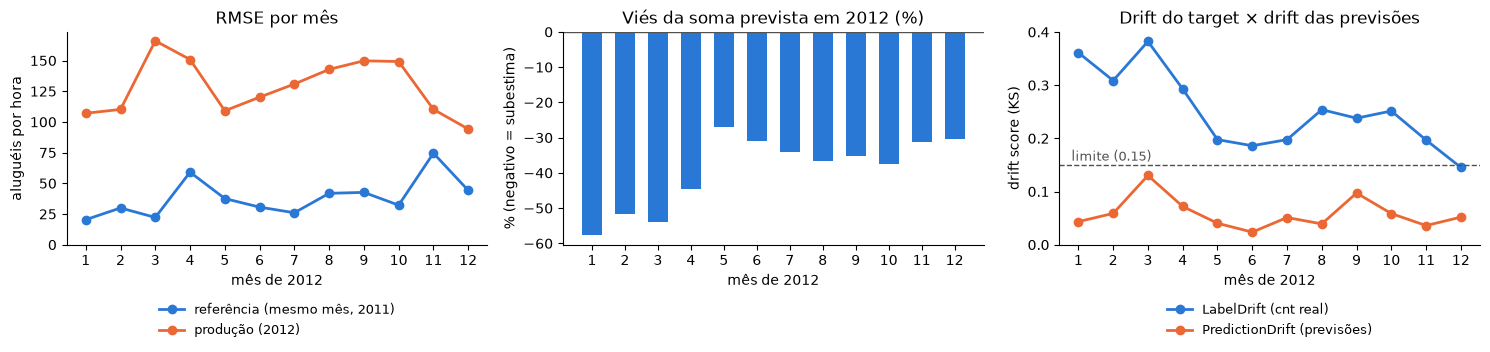

In [12]:
if DEEPCHECKS_AVAILABLE:
    meses = monthly.index
    fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))

    ax[0].plot(meses, monthly["RMSE ref"], marker="o", ms=6, lw=2, color=BLUE, label="referência (mesmo mês, 2011)")
    ax[0].plot(meses, monthly["RMSE 2012"], marker="o", ms=6, lw=2, color=ORANGE, label="produção (2012)")
    ax[0].set_title("RMSE por mês"); ax[0].set_ylabel("aluguéis por hora")
    ax[0].set_ylim(bottom=0)

    ax[1].bar(meses, monthly["viés 2012"] * 100, color=BLUE, width=0.6)
    ax[1].axhline(0, color=GRAY, lw=1)
    ax[1].set_title("Viés da soma prevista em 2012 (%)"); ax[1].set_ylabel("% (negativo = subestima)")

    ax[2].plot(meses, monthly["LabelDrift"], marker="o", ms=6, lw=2, color=BLUE, label="LabelDrift (cnt real)")
    ax[2].plot(meses, monthly["PredictionDrift"], marker="o", ms=6, lw=2, color=ORANGE, label="PredictionDrift (previsões)")
    ax[2].axhline(0.15, color=GRAY, lw=1, ls="--"); ax[2].text(0.8, 0.158, "limite (0.15)", color=GRAY, fontsize=9)
    ax[2].set_title("Drift do target × drift das previsões"); ax[2].set_ylabel("drift score (KS)")
    ax[2].set_ylim(bottom=0)

    for a in ax:
        a.set_xticks(range(1, 13)); a.set_xlabel("mês de 2012")
        a.spines[["top", "right"]].set_visible(False)
    for a in (ax[0], ax[2]):  # legenda abaixo do gráfico, sem cobrir as linhas
        a.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=1, fontsize=9)
    plt.tight_layout()
    fig.savefig(RUNS_DIR / "deepchecks_monthly_2012.png", dpi=130, bbox_inches="tight")
    plt.show()

**Leitura mês a mês:**

- **Desempenho e erro sistemático falham nos 12 meses.** O viés vai de −57% (janeiro) a −27% (maio) e nunca some: o crescimento do sistema é permanente, então o modelo de 2011 fica sempre "para trás".
- **`LabelDrift` falha em 11 de 12 meses.** É maior em jan–abr (0.29–0.38), justamente quando o uso de 2012 foi 1,8–2,5× o de 2011; em dezembro fica logo abaixo do limite (0.145).
- **`PredictionDrift` passa em todos os meses** (máx. 0.13 em março). De novo: olhando só as previsões, nada pareceria errado.
- **`FeatureDrift` também mostra o clima de verdade.** Janeiro/2012 foi 3 °C e março/2012 quase 5 °C mais quentes que em 2011 (drift de `temp` de 0.38 e 0.46), e novembro/2012 foi ~3 °C mais frio. Com a regra "no máximo 2 features acima de 0.2", só setembro e novembro reprovam. O março quente é também o mês de **maior RMSE** (166): clima atípico somado ao crescimento.
- **Outubro tem 708 horas** em vez de 744: são as ~36 horas do furacão Sandy com o sistema parado. **Nenhuma checagem pegou isso**, porque horas que não existem não viram nulos. Um monitor de **volume** (linhas esperadas × recebidas) é um complemento simples que o Deepchecks não cobre.
- O RMSE de referência mensal oscila (59 em abril, 75 em novembro) porque cada holdout mensal tem só ~170 horas. Em produção, vale usar janelas de referência maiores ou limites absolutos.

## 7 — O gate reprovou. E agora?

Testamos três respostas comuns no 2º semestre de 2012 (julho a dezembro), sempre usando só dados disponíveis **antes** de cada mês:

| Estratégia | Como |
|---|---|
| **A — modelo atual** | o modelo de 2011, sem mudanças |
| **B — re-treino ingênuo** | re-treina com 2011 + 1º semestre de 2012 |
| **C — janela recente** | re-treina **só** com o 1º semestre de 2012 |
| **D — recalibração** | modelo A × fator `soma real / soma prevista` das **últimas 4 semanas**, atualizado a cada mês |

In [13]:
h1 = df[is_2012 & (df["month"] <= 6)]
train_2011 = df[is_2011 & (df["date"].dt.day < 24)]

model_B = CountModel(build_pipeline(), metrics["sigma_used"]).fit(pd.concat([train_2011, h1]), pd.concat([train_2011, h1])[LABEL])
model_C = CountModel(build_pipeline(), metrics["sigma_used"]).fit(h1, h1[LABEL])

def recal_factor(m, base, dias=28):
    """Fator real/previsto nas `dias` anteriores ao início do mês m de 2012."""
    inicio = df.loc[is_2012 & (df["month"] == m), "datetime"].min()
    janela = df[(df["datetime"] < inicio) & (df["datetime"] >= inicio - pd.Timedelta(days=dias))]
    return janela[LABEL].sum() / base.predict(janela).sum()

rows = []
for m in range(7, 13):
    cur = df[is_2012 & (df["month"] == m)]
    k = recal_factor(m, model)
    for nome, mdl in [("A — modelo atual", model), ("B — re-treino ingênuo", model_B),
                      ("C — janela recente", model_C), ("D — recalibração", ScaledModel(model, k))]:
        p = mdl.predict(cur)
        rows.append({"mês": m, "estratégia": nome, "RMSE": rmse(cur[LABEL], p),
                     "viés": p.sum() / cur[LABEL].sum() - 1, "fator": k if nome.startswith("D") else np.nan})
strat = pd.DataFrame(rows)

h2 = df[is_2012 & (df["month"] >= 7)]
total = strat.groupby("estratégia").apply(
    lambda g: pd.Series({"RMSE médio mensal": g["RMSE"].mean(), "pior mês (RMSE)": g["RMSE"].max(),
                         "viés médio": g["viés"].mean()})
)
display(total.style.format({"RMSE médio mensal": "{:.1f}", "pior mês (RMSE)": "{:.1f}", "viés médio": "{:+.1%}"}))
print("fatores de recalibração por mês:", strat.dropna(subset=["fator"]).set_index("mês")["fator"].round(2).to_dict())

,RMSE médio mensal,pior mês (RMSE),viés médio
estratégia,,,
A — modelo atual,129.5,149.8,-34.2%
B — re-treino ingênuo,131.4,152.7,-34.4%
C — janela recente,79.5,91.7,-11.3%
D — recalibração,62.0,76.4,+0.2%


fatores de recalibração por mês: {7: 1.46, 8: 1.53, 9: 1.57, 10: 1.55, 11: 1.6, 12: 1.44}


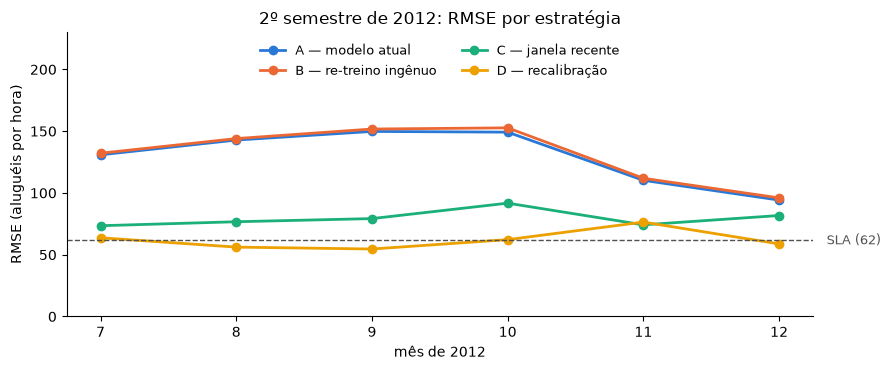

In [14]:
cores = {"A — modelo atual": BLUE, "B — re-treino ingênuo": ORANGE, "C — janela recente": AQUA, "D — recalibração": YELLOW}
fig, ax = plt.subplots(figsize=(9, 3.8))
for nome, g in strat.groupby("estratégia"):
    ax.plot(g["mês"], g["RMSE"], marker="o", ms=6, lw=2, color=cores[nome], label=nome)
RMSE_VAL = metrics["validation"]["modelo (expm1, sem correção)"]["RMSE"]
SLA_RMSE = 1.5 * RMSE_VAL
ax.axhline(SLA_RMSE, color=GRAY, lw=1, ls="--")
ax.text(12.35, SLA_RMSE, f"SLA ({SLA_RMSE:.0f})", color=GRAY, fontsize=9, va="center")
ax.set_xticks(range(7, 13)); ax.set_xlabel("mês de 2012"); ax.set_ylabel("RMSE (aluguéis por hora)")
ax.set_title("2º semestre de 2012: RMSE por estratégia"); ax.set_ylim(0, 230)
ax.legend(frameon=False, loc="upper center", fontsize=9, ncol=2)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
fig.savefig(RUNS_DIR / "deepchecks_strategies_2012H2.png", dpi=130, bbox_inches="tight")
plt.show()

### O gate aprova a recalibração?

Aqui há uma armadilha. A regra de **degradação relativa** (`TrainTestPerformance` com `relative_degradation`) compara o modelo na referência com o modelo na produção. Só que o `ScaledModel` multiplica **também** as previsões da referência de 2011 pelo fator de 2012, o que infla o erro de referência e faz a degradação parecer pequena. Seria uma aprovação falsa.

Para comparar A e D de forma justa, usamos uma regra **absoluta** (um SLA): RMSE mensal de no máximo **1,5× o RMSE da validação de 2011**, mais a regra de erro sistemático, que só olha a produção.

In [15]:
def sla_suite(sla):
    return Suite(
        "SLA mensal",
        TrainTestPerformance(scorers={"RMSE": "neg_rmse"}).add_condition_test_performance_greater_than(-sla),
        RegressionErrorDistribution().add_condition_systematic_error_ratio_to_rmse_less_than(0.30),
    )

if DEEPCHECKS_AVAILABLE:
    print(f"SLA: RMSE <= {SLA_RMSE:.1f} (1,5 × {RMSE_VAL:.1f})")
    rows = []
    for m in range(7, 13):
        ref_hold = df[is_2011 & (df["month"] == m) & (df["date"].dt.day >= 24)]
        cur = df[is_2012 & (df["month"] == m)]
        row = {"mês": m}
        for nome, mdl in [("A", model), ("D", ScaledModel(model, recal_factor(m, model)))]:
            r = sla_suite(SLA_RMSE).run(make_ds(ref_hold), make_ds(cur), model=mdl, feature_importance=feature_importance)
            row.update({f"RMSE {nome}": rmse_from(r, "Test"),
                        f"viés {nome}": mdl.predict(cur).sum() / cur[LABEL].sum() - 1,
                        f"SLA {nome}": status(r, "Train Test Performance"),
                        f"erro sist. {nome}": status(r, "Regression Error Distribution - Test")})
        rows.append(row)
    recal = pd.DataFrame(rows).set_index("mês")
    recal.to_csv(RUNS_DIR / "deepchecks_recalibration_2012H2.csv")
    display(recal.style.format({"RMSE A": "{:.1f}", "RMSE D": "{:.1f}", "viés A": "{:+.0%}", "viés D": "{:+.0%}"}))

SLA: RMSE <= 61.7 (1,5 × 41.1)


,RMSE A,viés A,SLA A,erro sist. A,RMSE D,viés D,SLA D,erro sist. D
mês,,,,,,,,
7,130.9,-34%,FAIL,FAIL,63.7,-4%,FAIL,PASS
8,142.8,-37%,FAIL,FAIL,56.2,-3%,PASS,PASS
9,149.8,-35%,FAIL,FAIL,54.6,+1%,PASS,PASS
10,149.2,-37%,FAIL,FAIL,62.2,-3%,FAIL,PASS
11,110.2,-31%,FAIL,FAIL,76.4,+10%,FAIL,PASS
12,94.2,-30%,FAIL,FAIL,58.7,+1%,PASS,PASS


**Leitura:**

- **B (re-treino ingênuo) não ajudou nada** (RMSE médio 131 contra 130 do modelo atual). A explicação mais provável: a árvore separa pelo `month`, e para julho–dezembro ela só tem exemplos de 2011. Re-treinar com mais dados não resolve quando **nenhuma feature representa a causa do drift** (o tamanho da base de usuários).
- **C (janela recente)** reduz o RMSE para 80 e o viés para −11%, mas joga fora o ano de 2011 inteiro e aprende o 2º semestre só a partir de inverno e primavera.
- **D (recalibração)** é a melhor das quatro: RMSE médio 62 e viés praticamente zero. O fator fica entre 1,44 e 1,60, coerente com o crescimento visto na EDA.
- **No gate:** com D, o **erro sistemático passa em todos os meses** (o viés foi resolvido), mas o **SLA de RMSE passa só em 3 de 6** (agosto, setembro e dezembro). Julho e outubro ficam logo acima do limite de 62, e novembro bem acima (76).

A recalibração é uma boa **mitigação** enquanto se prepara a correção de verdade: um modelo com uma feature que represente o nível de demanda recente (por exemplo, a média de `cnt` na mesma hora nos últimos 7 dias), re-treinado periodicamente.

## Conclusões

1. **O Deepchecks pegou o problema, mas pelas checagens certas.** `LabelDrift`, `TrainTestPerformance`, `RegressionErrorDistribution` e até `Identifier Label Correlation` acusam o crescimento. `FeatureDrift` e `PredictionDrift`, que são o que sobra quando não há rótulo, **não acusam nada**. Em *concept drift*, monitorar só as entradas dá falsa segurança.
2. **A referência precisa ser um holdout.** Se a referência fosse o próprio treino, o RMSE de referência seria 19 em vez de 41, e qualquer lote pareceria degradado.
3. **Sazonalidade exige comparar períodos equivalentes.** No monitoramento mensal, cada mês é comparado com o mesmo mês do ano anterior; comparar com o ano inteiro geraria alarmes de clima todo inverno.
4. **O gate diz "se"; as outras checagens dizem "onde".** `WeakSegmentsPerformance` localizou o erro no pico de volta do trabalho em dias úteis.
5. **Re-treinar não é sinônimo de corrigir.** O re-treino ingênuo não mudou nada; a recalibração resolveu o viés, mas não todo o erro. A correção definitiva exige uma feature que represente a causa do drift.
6. **Cuidado ao validar a correção:** a regra de degradação relativa aprovaria a recalibração por engano, porque o fator também distorce a referência. Para comparar estratégias, use limites absolutos.

### Próximos passos sugeridos
- Adicionar *lags* de demanda (mesma hora em t−24h e t−168h, média móvel de 7 dias) e refazer o experimento;
- Incluir um monitor de **volume** de linhas por período (o caso do furacão Sandy);
- Rodar o mesmo dataset no **Evidently** para comparar as duas ferramentas no mesmo cenário.